# Weapon-carrying risk prediction — modeling pipeline

This notebook goes from raw features to a deployable, uncertainty-aware risk model in nine steps. It is written so that someone who did **not** build it can read it top-to-bottom, understand each decision, and re-run it.

**Data discipline (used everywhere below).** The data is split once into **train / validation / test**, and each split has one job:

- **Train** — fit models; cross-validate during screening and tuning.
- **Validation** — make *choices* about the model: the decision **threshold**, (optionally) probability **calibration**, and the **conformal** calibration.
- **Test** — held out and used **only** to report final numbers. Nothing is fitted or selected on the test set.

**The 8 steps**

1. **Data & split** — load, inspect class balance, split into train/val/test.
2. **Setup** — device (GPU/CPU) detection and scoring utilities.
3. **Base-model screening** — a quick cross-validated comparison of many classifiers to shortlist promising families.
4. **Hyperparameter tuning** — tune the shortlist on train (CV); a validation leaderboard ranks them and saves each fitted model.
5. **Select the final model** — pick the one model to take forward.
6. **Operating point** — set the decision threshold on validation and report it on test; *optionally* calibrate probabilities (reviewer-suggested).
7. **Conformal prediction** — turn probabilities into calibrated prediction *sets*, so genuinely uncertain cases can be flagged for manual review instead of forced into a yes/no.
8. **Risk-tier stratification** *(optional)* — group students into Low / Moderate / High risk bands for a tiered-support policy.

# 1. Data & train/validation/test split

Load the feature table, check how imbalanced the outcome is (weapon-carrying is the rare, positive class), and split **once** into train / validation / test. `split_data` stratifies on the outcome so the class ratio is preserved in every split, and uses a fixed `random_state` for reproducibility. Only the train split is later resampled/cross-validated; validation and test are left untouched.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:

data = pd.read_csv('../../data/data_with_columnnames_RFE.csv')
print(data.shape)
data.head()

(61168, 16)


,weapon_carrying,MarijuanaUse,BelongToGang,BullyingOthers,GambledOnline,AlcoholUse,MissedSchoolUnsafe,TeacherBelievesInMe,NeverGambled,SmokedCigarettes,ThreatenedWithWeapon,PhysicalFightSchool,Age,ThreatenedToHurtSomeone,DatingViolenceVictim,SkippedSchoolDays
0,0,0,0,0,0,0,0,3,1,0,0,0,17,4,0,0
1,0,5,0,0,0,1,0,3,0,0,0,0,17,3,0,0
2,0,0,0,0,0,0,0,3,1,0,0,0,17,4,0,0
3,0,0,0,0,0,0,0,4,1,0,0,0,17,4,0,0
4,0,0,0,3,0,0,0,3,1,0,0,0,16,4,0,0


In [3]:
data.weapon_carrying.value_counts(normalize=True)

weapon_carrying
0    0.951838
1    0.048162
Name: proportion, dtype: float64

In [4]:
# Helper functions

# ----------------------------
# Imports
# ----------------------------
from collections import Counter
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score


# ----------------------------
# Train / Val / Test split
# ----------------------------
def split_data(data, target_col="outcome", test_size=0.30, random_state=42):
    """
    Split original data first.
    - Only the TRAIN split is used for CV + fitting.
    - Validation and Test are kept untouched (no resampling).
    """
    X = data.drop(columns=[target_col])
    y = data[target_col]

    # First split off a temp set (30% of data)
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        stratify=y,
        test_size=test_size,
        random_state=random_state
    )

    # Split temp into Val and Test (15% each if test_size=0.30)
    X_test, X_val, y_test, y_val = train_test_split(
        X_temp, y_temp,
        stratify=y_temp,
        test_size=0.50,
        random_state=random_state
    )

    print("Class counts (original, no resampling):")
    print("Train:", Counter(y_train))
    print("Val:  ", Counter(y_val))
    print("Test: ", Counter(y_test))

    return X_train, X_val, X_test, y_train, y_val, y_test

In [5]:
# create trainvalidation and test
X_train, X_val, X_test, y_train, y_val, y_test = split_data(data, target_col="weapon_carrying")

Class counts (original, no resampling):
Train: Counter({0: 40755, 1: 2062})
Val:   Counter({0: 8734, 1: 442})
Test:  Counter({0: 8733, 1: 442})


# 2. Setup: device acceleration & scoring utilities

In [6]:
import torch

# Check if MPS is available
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Metal GPU acceleration is activated!")
else:
    device = torch.device("cpu")
    print("MPS not available, using CPU.")

# Move a tensor to the Mac GPU
x = torch.ones(1, device=device)
print(x)

Metal GPU acceleration is activated!
tensor([1.], device='mps:0')


In [7]:
# ============================================================
#  Shared setup: device resolution, a CatBoost-safe ROC-AUC scorer,
#  and the validation-based threshold helper (reused across the notebook).
# ============================================================
import numpy as np
from sklearn.metrics import roc_auc_score, precision_recall_curve


def resolve_device(prefer_gpu=True, lightgbm_gpu=False, verbose=True):
    """
    Detect hardware once and return per-library device settings, with an
    automatic CPU fallback. Thread the returned dict through the model
    factories so 'device' is handled consistently everywhere.

    XGBoost/CatBoost GPU require CUDA (NVIDIA); on macOS they stay on CPU.
    LightGBM GPU needs an OpenCL/CUDA-enabled build, so it is opt-in
    (lightgbm_gpu=True) even when a GPU is present.
    """
    gpu = False
    if prefer_gpu:
        try:
            import torch
            gpu = bool(torch.cuda.is_available())
        except Exception:
            gpu = False
    cfg = {
        "gpu": gpu,
        "xgb_device": "cuda" if gpu else "cpu",
        "catboost_task_type": "GPU" if gpu else "CPU",
        "lgbm_device": "gpu" if (gpu and lightgbm_gpu) else "cpu",
    }
    if verbose:
        state = "CUDA GPU detected" if gpu else "no CUDA GPU -> CPU"
        print(f"[device] {state} | XGB={cfg['xgb_device']} "
              f"CatBoost={cfg['catboost_task_type']} LightGBM={cfg['lgbm_device']}")
    return cfg


def roc_auc_proba(estimator, X, y):
    """
    ROC-AUC scorer that calls predict_proba directly.

    scikit-learn >= 1.6 routes the built-in 'roc_auc' scorer through
    is_classifier(), which returns False for CatBoost wrappers lacking
    __sklearn_tags__ -> "Got a regressor ... predict_proba" and NaN scores.
    Calling predict_proba ourselves avoids that check and is numerically
    identical to scoring='roc_auc' for every classifier used here.
    """
    return roc_auc_score(y, estimator.predict_proba(X)[:, 1])


def optimal_f1_threshold(y_true, y_probs):
    """
    F1-maximizing decision threshold from a precision-recall sweep.
    Returns (threshold, f1). Call on the VALIDATION set, then apply the
    returned threshold to the test set for reporting.
    """
    precision, recall, thresholds = precision_recall_curve(y_true, y_probs)
    denom = precision + recall
    fscore = np.divide(2 * precision * recall, denom,
                       out=np.zeros_like(denom), where=denom != 0)
    ix = int(np.argmax(fscore))
    thr = thresholds[ix] if ix < len(thresholds) else thresholds[-1]
    return float(thr), float(fscore[ix])

# 3. Base-model screening (cross-validation)

Before spending time tuning, run a fast **5-fold cross-validated** comparison of many classifier families on the training data, both as-is (**Baseline**) and with **SMOTETomek** resampling. The boxplot and leaderboard (ROC-AUC per fold) show which families are worth carrying into tuning. Nothing here is final — it is a shortlist.

In [8]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, BaggingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="X does not have valid feature names")


def get_raw_classifiers(random_state=42, device=None):
    """
    Returns a dictionary of RAW classifiers (scaling/resampling happen in the
    pipeline, not here). GPU/CPU is controlled by `device` from resolve_device();
    if None it is auto-detected.
    """
    if device is None:
        device = resolve_device()

    models = {}

    # --- Linear / Distance / Neural ---
    models["LR"] = LogisticRegression(max_iter=2000, random_state=random_state,
                                      class_weight="balanced")
    models["LDA"] = LinearDiscriminantAnalysis()
    models["KNN"] = KNeighborsClassifier()
    models["ANN"] = MLPClassifier(hidden_layer_sizes=(100, 50), learning_rate_init=0.001,
                                  max_iter=3000, random_state=random_state, early_stopping=True)

    # --- Tree Ensembles ---
    models["RF"] = RandomForestClassifier(n_estimators=200, random_state=random_state,
                                          n_jobs=-1, class_weight="balanced")
    models["ET"] = ExtraTreesClassifier(n_estimators=200, random_state=random_state,
                                        n_jobs=-1, class_weight="balanced")
    models["ADA"] = AdaBoostClassifier(random_state=random_state)  # SAMME is the default now
    models["GBM"] = GradientBoostingClassifier(random_state=random_state)
    models["Bagging"] = BaggingClassifier(random_state=random_state, n_jobs=-1)

    # --- Advanced Gradient Boosting (device-aware) ---
    models["LightGBM"] = LGBMClassifier(objective="binary", random_state=random_state,
                                        verbose=-1, n_jobs=-1, class_weight="balanced",
                                        device=device["lgbm_device"])
    models["CatBoost"] = CatBoostClassifier(task_type=device["catboost_task_type"],
                                            thread_count=-1, allow_writing_files=False,
                                            loss_function="Logloss", verbose=0,
                                            random_state=random_state,
                                            auto_class_weights="Balanced")



    models["XGB"] = XGBClassifier(eval_metric="logloss", tree_method="hist", n_jobs=-1,
                                  random_state=random_state, device=device["xgb_device"])
    return models

In [9]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler

def baseline_pipeline(classifier, sampler=None):
    """
    Wraps a classifier in a robust pipeline.
    1. StandardScaler (Always applied - critical for KNN/ANN/LR)
    2. Sampler (Optional - Applied only if passed)
    3. Classifier
    """
    steps = [("scaler", StandardScaler())]
    
    if sampler is not None:
        steps.append(("sampler", sampler))
        
    steps.append(("model", classifier))
    
    return ImbPipeline(steps=steps)

In [10]:
#  Define CV Runner ---
from sklearn.model_selection import StratifiedKFold, cross_val_score
import pandas as pd
import numpy as np

def run_cv_comparison(X, y, classifiers, sampler=None, sampler_name="Baseline", cv=5,
                      scoring=roc_auc_proba):
    """CV comparison. Uses the CatBoost-safe roc_auc_proba scorer by default."""
    results_list = []
    cv_strategy = StratifiedKFold(n_splits=cv, shuffle=True, random_state=42)
    print(f"--- Running {cv}-Fold CV: {sampler_name} ---")

    for name, clf in classifiers.items():
        pipeline = baseline_pipeline(clf, sampler)
        try:
            scores = cross_val_score(pipeline, X, y, cv=cv_strategy, scoring=scoring, n_jobs=-1)
            for score in scores:
                results_list.append({"Model": name, "Strategy": sampler_name, "ROC_AUC": score})
        except Exception as e:
            print(f"!! Failed {name}: {e}")

    return pd.DataFrame(results_list)

In [11]:
import plotly.express as px

def plot_performance_comparison(results_df, metric="ROC_AUC", title="Model Selection: Baseline vs. Resampling"):
    """
    Plots a grouped boxplot to compare distribution of scores across folds.
    Args:
        results_df: DataFrame containing CV results
        metric: Column name to plot (e.g., "ROC_AUC", "F1")
        title: Title of the chart
    """
    # 1. Calculate sorting order (Best Median Score first)
    # We sort based on the median of the metric
    sort_order = results_df.groupby("Model")[metric].median().sort_values(ascending=False).index.tolist()

    # 2. Create the Plot
    fig = px.box(
        results_df, 
        x="Model", 
        y=metric, 
        color="Strategy", 
        title=title,
        category_orders={"Model": sort_order}, # Apply the sorting
        points="all",       # Show individual fold dots
        hover_data=["Model", "Strategy", metric]
    )

    # 3. Style Updates
    fig.update_layout(
        yaxis_title=f"Cross-Validated {metric}", # <--- Now dynamic!
        xaxis_title="Classifier",
        boxmode="group",    # Groups boxes side-by-side
        template="plotly_white",
        legend=dict(
            orientation="h", 
            y=1.1, 
            x=0.5, 
            xanchor="center",
            title=None
        ),
        height=600
    )
    
    # Optional: Add a reference line only if plotting ROC-AUC
    if metric == "ROC_AUC":
        fig.add_hline(y=0.8, line_dash="dot", line_color="gray", opacity=0.5, annotation_text="Target (0.8)")

    fig.show()

In [12]:
# Get Classifiers (device auto-detected: GPU if a CUDA GPU is present, else CPU)
device_cfg = resolve_device()
classifiers = get_raw_classifiers(random_state=42, device=device_cfg)

# Run CV for Baseline
df_baseline = run_cv_comparison(
    X_train, y_train, classifiers, sampler=None, sampler_name="Baseline"
)

# Run CV for SMOTETomek
from imblearn.combine import SMOTETomek
smt = SMOTETomek(random_state=42, sampling_strategy=0.4)  # minority resampled to 40%

df_smote = run_cv_comparison(
    X_train, y_train, classifiers, sampler=smt, sampler_name="SMOTETomek"
)

# Combine + plot
final_results = pd.concat([df_baseline, df_smote], ignore_index=True)
plot_performance_comparison(final_results)

[device] no CUDA GPU -> CPU | XGB=cpu CatBoost=CPU LightGBM=cpu
--- Running 5-Fold CV: Baseline ---
--- Running 5-Fold CV: SMOTETomek ---


In [13]:
def get_leaderboard(results_df, metric="ROC_AUC"):
    """
    Aggregates the fold results into a clean leaderboard.
    """
    summary = results_df.groupby(["Model", "Strategy"])[metric].agg(["mean", "std", "min", "max"])
    
    # Rename for readability
    summary = summary.rename(columns={"mean": "Mean AUC", "std": "Std Dev"})
    
    # Sort by Best Mean Score
    summary = summary.sort_values(by="Mean AUC", ascending=False)
    
    return summary.style.background_gradient(subset=["Mean AUC"], cmap="Greens")

# Execute Table
leaderboard = get_leaderboard(final_results)
display(leaderboard)

# 4. Hyperparameter tuning

Tune a shortlist of models on the **training** data with cross-validated search (`halving_random` by default). Each model's best estimator is scored on the **validation** set and saved to `./without_resampling_baseline/<Model>/` (model + best params + validation metrics). The printed table is the **validation leaderboard** used to choose a winner in Step 5.

`compute_metrics` (defined here) is the single metrics function reused throughout, with a focus on the minority class (precision/recall/F1 for weapon-carrying) plus imbalance-robust summaries (MCC, Cohen's κ) and probability metrics (ROC-AUC, PR-AUC, Brier).

In [14]:
import os
import json
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             cohen_kappa_score, matthews_corrcoef, brier_score_loss, 
                             roc_auc_score, average_precision_score)

# 1. Your Custom Metrics Function
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             cohen_kappa_score, matthews_corrcoef, brier_score_loss, 
                             roc_auc_score, average_precision_score, confusion_matrix)

def compute_metrics(y_true, y_pred, y_prob=None, pos_label=1):
    """
    Computes metrics with a focus on the Minority Class (Class 1).
    """
    # Calculate confusion matrix to get raw numbers (TN, FP, FN, TP)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    
    # Specificity (Recall of the Negative Class) - How well do we identify safe students?
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    pos_label = 1 # Weapon
    neg_label = 0 # No Weapon
    
    out = {
        # --- GLOBAL METRICS (Overall Health) ---
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Cohen Kappa": float(cohen_kappa_score(y_true, y_pred)),
        "Matthews Corrcoef": float(matthews_corrcoef(y_true, y_pred)), # The best single-number summary for imbalance
        "Brier Score Loss": float(brier_score_loss(y_true, y_pred)),
        
        # --- CLASS 1 METRICS (The Critical Ones) ---
        # Precision: Of those we FLAGGED, how many actually had weapons? (Avoids false accusations)
        "Precision (Class 1)": float(precision_score(y_true, y_pred, pos_label=pos_label, zero_division=0)),
        
        # Recall: Of those who HAD weapons, how many did we catch? (Safety critical)
        "Recall (Class 1)": float(recall_score(y_true, y_pred, pos_label=pos_label, zero_division=0)),
        
        # F1: Harmonic mean of the two above
        "F1 (Class 1)": float(f1_score(y_true, y_pred, pos_label=pos_label, zero_division=0)),
        
        # --- CLASS 0 METRICS (Context) ---
        "Specificity (Class 0 Recall)": float(specificity),
    }

    if y_prob is not None:
        out["ROC AUC"] = float(roc_auc_score(y_true, y_prob))
        # PR-AUC is often MORE important than ROC-AUC for imbalanced data
        out["PR-AUC"] = float(average_precision_score(y_true, y_prob, pos_label=pos_label))
    else:
        out["ROC AUC"] = None
        out["PR-AUC"] = None
        
    return out

# 2. Artifact Saver
def save_model_artifacts(model_name, model, params, metrics, base_path="./model_results"):
    """
    Saves model, parameters, and metrics into a dedicated folder.
    Structure: ./model_results/XGBoost/
    """
    # Create directory: e.g., ./model_results/XGBoost
    save_dir = os.path.join(base_path, model_name)
    os.makedirs(save_dir, exist_ok=True)
    
    # A. Save Model Object
    model_path = os.path.join(save_dir, "model.joblib")
    joblib.dump(model, model_path)
    
    # B. Save Best Hyperparameters
    params_path = os.path.join(save_dir, "best_params.json")
    with open(params_path, "w") as f:
        json.dump(params, f, indent=4)
        
    # C. Save Metrics
    metrics_path = os.path.join(save_dir, "validation_metrics.csv")
    pd.DataFrame([metrics]).to_csv(metrics_path, index=False)
    
    print(f"    [Saved] Artifacts stored in: {save_dir}")

In [15]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.linear_model import LogisticRegression

def get_classifiers(random_state=42, device=None):
    """Tuning-stage classifiers. GPU/CPU via `device` from resolve_device()."""
    if device is None:
        device = resolve_device()
    models = {}

    models["XGB"] = XGBClassifier(
        eval_metric="logloss", tree_method="hist", device=device["xgb_device"],
        random_state=random_state
    )
    models["LightGBM"] = LGBMClassifier(
        objective="binary", verbose=-1, class_weight="balanced",
        random_state=random_state, device=device["lgbm_device"]
    )
    models["RF"] = RandomForestClassifier(
        class_weight="balanced", n_jobs=-1, random_state=random_state
    )
    models["CatBoost"] = CatBoostClassifier(
        loss_function="Logloss", verbose=0, auto_class_weights="Balanced",
        random_state=random_state, task_type=device["catboost_task_type"],
        allow_writing_files=False
    )
    models["HGB"] = HistGradientBoostingClassifier(
        class_weight="balanced", random_state=random_state, early_stopping=True
    )
    models["GBM"] = GradientBoostingClassifier(random_state=random_state)
    # NOTE: the 'algorithm' argument was removed in scikit-learn 1.8 (SAMME is
    # now the only/default), so we no longer pass algorithm='SAMME'.
    models["ADA"] = AdaBoostClassifier(random_state=random_state)
    models["LR"] = LogisticRegression(
        class_weight="balanced", random_state=random_state, max_iter=1000
    )
    return models
def get_grids():
    grids = {}
    
    # --- XGBoost ---
    grids["XGB"] = {
        "model__learning_rate": [0.01, 0.05, 0.1], 
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [3, 5, 7],
        "model__subsample": [0.7, 0.9],
        "model__colsample_bytree": [0.7, 0.9],
        "model__reg_lambda": [1, 5, 10]
    }
    
    # --- LightGBM ---
    grids["LightGBM"] = {
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__num_leaves": [31, 50, 80],
        "model__max_depth": [-1, 10, 20],
        "model__subsample": [0.7, 0.9]
    }
    
    # --- Random Forest ---
    grids["RF"] = {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [2, 5]
    }

    # --- CatBoost ---
    grids["CatBoost"] = {
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__depth": [4, 6, 8],
        "model__l2_leaf_reg": [1, 3, 5, 7],
        "model__iterations": [200, 500]
    }

    # --- HGB ---
    grids["HGB"] = {
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__max_iter": [200, 400],
        "model__max_leaf_nodes": [31, 50],
        "model__l2_regularization": [0, 1, 10]
    }
    
    # --- GBM Grid ---
    grids["GBM"] = {
        "model__n_estimators": [100, 300],
        "model__learning_rate": [0.01, 0.1],
        "model__max_depth": [3, 5],
        "model__subsample": [0.8, 1.0]
    }

    # --- AdaBoost Grid ---
    grids["ADA"] = {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.01, 0.1, 1.0]
    }

    # --- Logistic Regression Grid ---
    # Using 'liblinear' solver as it works well with L1 and L2 for smaller datasets
    grids["LR"] = {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__penalty": ['l1', 'l2'],
        "model__solver": ['liblinear']
    }
    return grids

In [16]:
from sklearn.experimental import enable_halving_search_cv  # Essential for Halving
from sklearn.model_selection import (
    GridSearchCV, 
    RandomizedSearchCV, 
    HalvingGridSearchCV, 
    HalvingRandomSearchCV
)

def get_searcher_object(pipeline, param_grid, strategy, cv=5, n_iter=20, random_state=42):
    """
    Factory function that returns the configured SearchCV object.
    
    Args:
        strategy (str): 'grid', 'random', 'halving_random', or 'halving_grid'
    """
    common_params = {
        "estimator": pipeline,
        "param_grid": param_grid,
        "cv": cv,
        "scoring": roc_auc_proba,
        "n_jobs": -1,
        "verbose": 1
    }

    # --- Strategy 1: Standard Randomized Search (Balanced) ---
    if strategy == "random":
        return RandomizedSearchCV(
            **common_params,
            n_iter=n_iter,
            random_state=random_state
        )

    # --- Strategy 2: Halving Random Search (Fastest for Large Data) ---
    elif strategy == "halving_random":
        return HalvingRandomSearchCV(
            estimator=pipeline,
            param_distributions=param_grid, # Note: Arg name changes to param_distributions
            cv=cv,
            scoring=roc_auc_proba,
            n_jobs=-1,
            verbose=1,
            random_state=random_state,
            n_candidates=n_iter,      # How many to sample initially
            min_resources='exhaust',  # Auto-calculate starting size
            factor=3
        )

    # --- Strategy 3: Standard Grid Search (Most Thorough, Slowest) ---
    elif strategy == "grid":
        return GridSearchCV(
            **common_params
            # n_iter is ignored here
        )

    # --- Strategy 4: Halving Grid Search (Thorough but faster than Grid) ---
    elif strategy == "halving_grid":
        return HalvingGridSearchCV(
            **common_params,
            min_resources='exhaust',
            factor=3,
            random_state=random_state
        )
    
    else:
        raise ValueError(f"Unknown search strategy: {strategy}")

In [17]:

from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

def tune_and_save_experiment(
    classifiers, grids, 
    X_train, y_train, 
    X_val, y_val,   
    sampler=None,  # <--- Default is now None
    search_strategy="halving_random", 
    n_iter=20,
    output_folder="./experiment_results"
):
    summary_list = []
    
    # Update output folder name if no sampler is used, to avoid overwriting
    if sampler is None:
        output_folder = output_folder + "_baseline"
        
    print(f"--- Starting Pipeline | Strategy: {search_strategy} | Sampler: {sampler} ---")
    print(f"--- Output Folder: {output_folder} ---")

    for name, clf in classifiers.items():
        if name not in grids:
            continue
            
        print(f"\n>>> Processing: {name}")
        
        # --- MODIFIED PIPELINE CONSTRUCTION ---
        # 1. Start with Scaler
        steps = [("scaler", StandardScaler())]
        
        # 2. Add Sampler ONLY if it exists
        if sampler is not None:
            steps.append(("sampler", sampler))
            
        # 3. Add Model
        steps.append(("model", clf))
        
        # 4. Create Pipeline
        pipeline = ImbPipeline(steps)
        # --------------------------------------
        
        try:
            # Get Searcher (Using your factory or direct logic)
            # Assuming you kept the 'get_searcher_object' function:
            search = get_searcher_object(
                pipeline=pipeline, 
                param_grid=grids[name], 
                strategy=search_strategy, 
                cv=5, 
                n_iter=n_iter
            )
            
            # Fit
            search.fit(X_train, y_train)
            best_model = search.best_estimator_
            
            # Evaluate on Val
            val_probs = best_model.predict_proba(X_val)[:, 1]
            val_preds = best_model.predict(X_val)
            
            # Metrics
            metrics = compute_metrics(y_val, val_preds, val_probs)
            
            # Save
            save_model_artifacts(
                model_name=name,
                model=best_model,
                params=search.best_params_,
                metrics=metrics,
                base_path=output_folder
            )
            
            summary_entry = {"Model": name}
            summary_entry.update(metrics)
            summary_list.append(summary_entry)
            
        except Exception as e:
            print(f"!!! Error processing {name}: {e}")

    return pd.DataFrame(summary_list).sort_values(by="ROC AUC", ascending=False)

In [18]:
# Setup
from imblearn.combine import SMOTETomek

# Load ALL models
device_cfg = resolve_device()
all_models = get_classifiers(device=device_cfg)   # GPU if available, else CPU
all_grids = get_grids()

# Select ONLY what you want to run right now
selected_names = ["XGB", "CatBoost", "GBM", "LR", "ADA"] 
selected_models = {k: v for k, v in all_models.items() if k in selected_names}

# resampler
smt = SMOTETomek(random_state=42, sampling_strategy='not majority')

# Execute
leaderboard = tune_and_save_experiment(
    classifiers=selected_models,
    grids=all_grids,
    X_train=X_train, 
    y_train=y_train,
    X_val=X_val,    
    y_val=y_val,
    sampler=None,   # <--- THE KEY CHANGE
    #sampler=sampler,
    search_strategy="halving_random", # Options: 'grid', 'random', 'halving_random', 'halving_grid'
    n_iter=50,      # Test 50 candidates per model
    output_folder="./without_resampling"
)

# View Results
print("\n--- Validation Set Leaderboard ---")
display(leaderboard)

[device] no CUDA GPU -> CPU | XGB=cpu CatBoost=CPU LightGBM=cpu
--- Starting Pipeline | Strategy: halving_random | Sampler: None ---
--- Output Folder: ./without_resampling_baseline ---

>>> Processing: XGB
n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 4
min_resources_: 1585
max_resources_: 42817
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 50
n_resources: 1585
Fitting 5 folds for each of 50 candidates, totalling 250 fits
----------
iter: 1
n_candidates: 17
n_resources: 4755
Fitting 5 folds for each of 17 candidates, totalling 85 fits
----------
iter: 2
n_candidates: 6
n_resources: 14265
Fitting 5 folds for each of 6 candidates, totalling 30 fits
----------
iter: 3
n_candidates: 2
n_resources: 42795
Fitting 5 folds for each of 2 candidates, totalling 10 fits
    [Saved] Artifacts stored in: ./without_resampling_baseline/XGB

>>> Processing: CatBoost
n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 4
min_resources_: 1585
max_r

/Users/qge5yv/miniforge3/envs/p310/lib/python3.10/site-packages/sklearn/model_selection/_search.py:317: UserWarning:

The total space of parameters 16 is smaller than n_iter=50. Running 16 iterations. For exhaustive searches, use GridSearchCV.



----------
iter: 1
n_candidates: 6
n_resources: 14271
Fitting 5 folds for each of 6 candidates, totalling 30 fits
----------
iter: 2
n_candidates: 2
n_resources: 42813
Fitting 5 folds for each of 2 candidates, totalling 10 fits
    [Saved] Artifacts stored in: ./without_resampling_baseline/GBM

>>> Processing: ADA
n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 4757
max_resources_: 42817
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 9
n_resources: 4757
Fitting 5 folds for each of 9 candidates, totalling 45 fits


/Users/qge5yv/miniforge3/envs/p310/lib/python3.10/site-packages/sklearn/model_selection/_search.py:317: UserWarning:

The total space of parameters 9 is smaller than n_iter=50. Running 9 iterations. For exhaustive searches, use GridSearchCV.



----------
iter: 1
n_candidates: 3
n_resources: 14271
Fitting 5 folds for each of 3 candidates, totalling 15 fits
----------
iter: 2
n_candidates: 1
n_resources: 42813
Fitting 5 folds for each of 1 candidates, totalling 5 fits
    [Saved] Artifacts stored in: ./without_resampling_baseline/ADA

>>> Processing: LR
n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 4757
max_resources_: 42817
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 10
n_resources: 4757
Fitting 5 folds for each of 10 candidates, totalling 50 fits
----------
iter: 1
n_candidates: 4
n_resources: 14271
Fitting 5 folds for each of 4 candidates, totalling 20 fits


/Users/qge5yv/miniforge3/envs/p310/lib/python3.10/site-packages/sklearn/model_selection/_search.py:317: UserWarning:

The total space of parameters 10 is smaller than n_iter=50. Running 10 iterations. For exhaustive searches, use GridSearchCV.



----------
iter: 2
n_candidates: 2
n_resources: 42813
Fitting 5 folds for each of 2 candidates, totalling 10 fits
    [Saved] Artifacts stored in: ./without_resampling_baseline/LR

--- Validation Set Leaderboard ---


,Model,Accuracy,Cohen Kappa,Matthews Corrcoef,Brier Score Loss,Precision (Class 1),Recall (Class 1),F1 (Class 1),Specificity (Class 0 Recall),ROC AUC,PR-AUC
0,XGB,0.969486,0.571510,0.602866,0.030514,0.846154,0.447964,0.585799,0.995878,0.919251,0.629045
2,GBM,0.968832,0.554942,0.590633,0.031168,0.851351,0.427602,0.569277,0.996222,0.918534,0.632541
1,CatBoost,0.874455,0.330849,0.401238,0.125545,0.249294,0.798643,0.379978,0.878292,0.918503,0.620236
3,ADA,0.967960,0.534640,0.574800,0.032040,0.852381,0.404977,0.549080,0.996451,0.917206,0.616726
4,LR,0.884372,0.348483,0.412431,0.115628,0.264280,0.785068,0.395442,0.889398,0.914592,0.613081


# 5. Select the final model

Based on the validation leaderboard above, take **one** model forward. Everything after this point operates on that single selected model, so the rest of the notebook stays unambiguous.

In [19]:
# From the validation leaderboard above we take ONE model forward as the final model.
# GBM was the strongest candidate here; change SELECTED_MODEL to any tuned model's
# folder name (e.g. "XGB", "CatBoost", "LR") to report a different one instead.
import os
import joblib

SELECTED_MODEL = "GBM"

_model_path = f"./without_resampling_baseline/{SELECTED_MODEL}/model.joblib"
tuned_model = joblib.load(_model_path)
print(f"Selected model: {SELECTED_MODEL}")
print(f"Loaded tuned estimator from: {_model_path}")

Selected model: GBM
Loaded tuned estimator from: ./without_resampling_baseline/GBM/model.joblib


# 6. Operating point: decision threshold (and optional calibration)

A probability model still needs a **decision rule**. Two things happen here, in order:

1. **Threshold optimization (always).** We pick the F1-optimal probability cutoff **on the validation set**, then apply that fixed threshold to the **test set** to report precision/recall/F1 at the operating point. Choosing the threshold on validation (not test) is exactly the reviewer's point: the threshold is a model choice, so tuning it on the test set would leak test information. ROC-AUC / PR-AUC / Brier are threshold-independent and unaffected.
2. **Probability calibration (optional, reviewer-suggested).** Set `CALIBRATE = True` to fit an isotonic calibrator **on validation** and check calibration quality (Brier + reliability diagram) **on test**. When enabled, the calibrated model becomes the final model.

The result is a single `FINAL_MODEL` and `FINAL_THRESHOLD` that Steps 7–8 reuse — no duplicated evaluation, one results folder (`./final_results/`).

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix, precision_recall_curve, average_precision_score
import os

def set_apa_style():
    """
    Sets Matplotlib parameters to meet APA 7 standards.
    """
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
    plt.rcParams['font.size'] = 12
    plt.rcParams['axes.labelsize'] = 12
    plt.rcParams['axes.titlesize'] = 14
    plt.rcParams['xtick.labelsize'] = 11
    plt.rcParams['ytick.labelsize'] = 11
    plt.rcParams['axes.grid'] = False
    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.edgecolor'] = 'black'
    plt.rcParams['axes.linewidth'] = 1.0

def plot_publication_graphs(y_test, y_probs, y_preds, model_name, output_dir):
    """
    Generates APA-compliant plots.
    Saves as .png and .tiff (Uncompressed).
    """
    set_apa_style()
    
    # --- 1. Confusion Matrix ---
    cm = confusion_matrix(y_test, y_preds)
    plt.figure(figsize=(5, 4))
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greys', cbar=False, 
                annot_kws={"size": 14, "weight": "bold"},
                linewidths=1, linecolor='black') 
    
    plt.ylabel('Actual Label', fontweight='bold')
    plt.xlabel('Predicted Label', fontweight='bold')
    plt.tight_layout()
    
    # Save PNG
    plt.savefig(os.path.join(output_dir, "fig_confusion_matrix.png"), dpi=300, bbox_inches='tight')
    
    # Save TIFF (Argument removed here)
    plt.savefig(os.path.join(output_dir, "fig_confusion_matrix.tiff"), dpi=300, bbox_inches='tight')
    plt.close()

    # --- 2. ROC Curve ---
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = auc(fpr, tpr)
    
    plt.figure(figsize=(6, 5))
    
    label_text = f'{model_name} (AUC = {roc_auc:.2f})'
    
    plt.plot(fpr, tpr, color='black', lw=2, label=label_text)
    plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Random Chance')
    
    plt.xlim([-0.01, 1.0])
    plt.ylim([0.0, 1.02])
    plt.xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
    plt.ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
    
    plt.legend(loc="lower right", frameon=False)
    plt.tight_layout()
    
    plt.savefig(os.path.join(output_dir, "fig_roc_curve.png"), dpi=300, bbox_inches='tight')
    plt.savefig(os.path.join(output_dir, "fig_roc_curve.tiff"), dpi=300, bbox_inches='tight')
    plt.close()

    # --- 3. Precision-Recall Curve ---
    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    
    plt.figure(figsize=(6, 5))
    
    label_text = f'{model_name} (PR-AUC = {pr_auc:.2f})'
    
    plt.plot(recall, precision, color='black', lw=2, label=label_text)
    
    plt.xlabel('True Positive Rate (Recall)', fontweight='bold')
    plt.ylabel('Positive Predictive Value (Precision)', fontweight='bold')
    
    plt.ylim([0.0, 1.02])
    plt.xlim([0.0, 1.0])
    plt.legend(loc="lower left", frameon=False)
    plt.tight_layout()
    
    plt.savefig(os.path.join(output_dir, "fig_pr_curve.png"), dpi=300, bbox_inches='tight')
    plt.savefig(os.path.join(output_dir, "fig_pr_curve.tiff"), dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"    [APA Style] High-res figures for {model_name} saved to: {output_dir}")

In [21]:
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibratedClassifierCV
import joblib


def calculate_brier_score(y_true, y_probs):
    """Brier score = mean squared error of the predicted probabilities (0 = best, 1 = worst)."""
    return brier_score_loss(y_true, y_probs)


def apply_calibration(model, X_val, y_val, method="isotonic"):
    """
    Fit a probability calibrator on the VALIDATION set for an already-trained model.
      method: 'isotonic' (non-parametric) or 'sigmoid' (Platt scaling).

    Uses FrozenEstimator on scikit-learn >= 1.6 (where cv='prefit' is deprecated and
    was removed in 1.8) and falls back to cv='prefit' on older versions, so the same
    code runs regardless of the installed scikit-learn.
    """
    print(f"    [Calibrating] Fitting {method} calibrator on the validation set...")
    try:
        from sklearn.frozen import FrozenEstimator            # scikit-learn >= 1.6
        calibrated = CalibratedClassifierCV(FrozenEstimator(model), method=method)
    except Exception:
        calibrated = CalibratedClassifierCV(model, method=method, cv="prefit")  # older sklearn
    calibrated.fit(X_val, y_val)
    return calibrated

In [22]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
import os

def set_apa_style():
    """Sets Matplotlib parameters to meet APA 7 standards."""
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
    plt.rcParams['font.size'] = 12
    plt.rcParams['axes.labelsize'] = 12
    plt.rcParams['axes.titlesize'] = 14
    plt.rcParams['xtick.labelsize'] = 11
    plt.rcParams['ytick.labelsize'] = 11
    plt.rcParams['axes.grid'] = False
    plt.rcParams['figure.facecolor'] = 'white'
    plt.rcParams['axes.edgecolor'] = 'black'
    plt.rcParams['axes.linewidth'] = 1.0

def plot_calibration_curve_apa(y_true, y_probs, model_name, brier_score, output_dir):
    """
    Generates and saves a high-res Calibration Curve (Reliability Diagram).
    Saves both PNG and TIFF (300 DPI).
    """
    set_apa_style()
    
    # 1. Compute Curve Data
    # n_bins=10 is standard for decile analysis
    prob_true, prob_pred = calibration_curve(y_true, y_probs, n_bins=10)
    
    # 2. Create Plot
    plt.figure(figsize=(6, 6))
    
    # Perfect calibration (Dotted line)
    plt.plot([0, 1], [0, 1], "k:", linewidth=1.5, label="Perfectly Calibrated")
    
    # Model curve
    label_text = f"{model_name}\n(Brier Score = {brier_score:.4f})"
    plt.plot(prob_pred, prob_true, "s-", linewidth=2, color='black', label=label_text)
    
    # 3. Scientific Labels
    plt.xlabel("Mean Predicted Probability (Confidence)", fontweight='bold')
    plt.ylabel("Fraction of Positives (Observed Accuracy)", fontweight='bold')
    
    # 4. Formatting
    plt.legend(loc="upper left", frameon=False, fontsize=11)
    plt.xlim([-0.02, 1.02])
    plt.ylim([-0.02, 1.02])
    plt.tight_layout()
    
    # 5. Save
    os.makedirs(output_dir, exist_ok=True)
    plt.savefig(os.path.join(output_dir, "fig_calibration_curve.png"), dpi=300, bbox_inches='tight')
    plt.savefig(os.path.join(output_dir, "fig_calibration_curve.tiff"), dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"    [Plot] Calibration curve saved to {output_dir}")

In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score

def get_full_publication_metrics(model, X_test, y_test, optimized_threshold):
    """
    Computes the complete metric set for the final Calibrated Model
    using the Optimized Threshold.
    """
    # 1. Get Calibrated Probabilities
    y_probs = model.predict_proba(X_test)[:, 1]
    
    # 2. Apply Optimized Threshold (Hard Predictions)
    y_preds = (y_probs >= optimized_threshold).astype(int)
    
    # 3. Compute Standard Metrics (Accuracy, Precision, Recall, F1, etc.)
    # Reuse your existing function
    metrics = compute_metrics(y_test, y_preds, y_probs)
    
    # 4. Explicitly add Threshold & Brier for the report
    metrics['Optimized_Threshold'] = optimized_threshold
    metrics['Brier_Score'] = brier_score_loss(y_test, y_probs)
    
    return metrics

In [24]:
# ============================================================
#  Step 6 helpers - set the OPERATING POINT for the chosen model.
#
#  Golden rule (what the reviewer asked for): the decision threshold is chosen
#  on the VALIDATION set and then applied UNCHANGED to the TEST set. The test
#  set is used only to report; nothing is tuned on it. Threshold-independent
#  metrics (ROC-AUC, PR-AUC, Brier) do not depend on this choice.
# ============================================================
import os
import joblib
import pandas as pd


def evaluate_on_test(model, X_val, y_val, X_test, y_test, model_name, output_base):
    """
    Report `model` on the TEST set at two operating points:
      * the default 0.5 cutoff (fixed), and
      * the F1-optimal threshold TUNED ON VALIDATION, applied unchanged to test.
    Saves one metrics table, the APA figures, the model, and the threshold.
    Returns {"threshold": float, "metrics": DataFrame}.
    """
    save_dir = os.path.join(output_base, model_name)
    os.makedirs(save_dir, exist_ok=True)

    # 1) threshold chosen on VALIDATION (never on test)
    thr, val_f1 = optimal_f1_threshold(y_val, model.predict_proba(X_val)[:, 1])
    print(f"[{model_name}] validation-tuned threshold = {thr:.4f} (validation F1 = {val_f1:.4f})")

    # 2) probabilities on TEST -> metrics at both operating points
    probs = model.predict_proba(X_test)[:, 1]
    rows = []
    for label, t, src in [("Default", 0.5, "fixed(0.5)"), ("Optimized", thr, "validation")]:
        m = compute_metrics(y_test, (probs >= t).astype(int), probs)
        m["Threshold_Type"] = label
        m["Threshold_Value"] = t
        m["Threshold_Source"] = src
        rows.append(m)
    metrics_df = pd.DataFrame(rows)

    print("\nTest-set metrics (report the 'Optimized' row):")
    display(metrics_df[["Threshold_Type", "Threshold_Value", "Precision (Class 1)",
                        "Recall (Class 1)", "F1 (Class 1)", "Specificity (Class 0 Recall)",
                        "ROC AUC", "PR-AUC"]])

    # 3) persist a single, clearly named set of artifacts
    metrics_df.to_csv(os.path.join(save_dir, "test_metrics.csv"), index=False)
    plot_publication_graphs(y_test, probs, (probs >= thr).astype(int), model_name, save_dir)
    joblib.dump(model, os.path.join(save_dir, "final_model.joblib"))
    joblib.dump(thr, os.path.join(save_dir, "decision_threshold.joblib"))
    print(f"[Saved] {save_dir}")
    return {"threshold": thr, "metrics": metrics_df}


def calibrate_and_diagnose(model, X_val, y_val, X_test, y_test, model_name, output_base,
                           method="isotonic"):
    """
    OPTIONAL (reviewer-suggested) probability calibration.
    Fits the calibrator on the VALIDATION set, then reports calibration quality
    (Brier score + reliability diagram) on the TEST set. Returns the calibrated
    model, which can then be passed through evaluate_on_test like any other model.
    """
    save_dir = os.path.join(output_base, f"{model_name}_calibrated")
    os.makedirs(save_dir, exist_ok=True)
    calibrated = apply_calibration(model, X_val, y_val, method=method)
    brier = calculate_brier_score(y_test, calibrated.predict_proba(X_test)[:, 1])
    print(f"[{model_name}] Brier score after {method} calibration (test) = {brier:.4f}")
    plot_calibration_curve_apa(y_test, calibrated.predict_proba(X_test)[:, 1],
                               f"{model_name} ({method})", brier, save_dir)
    return calibrated

In [25]:
# ------------------------------------------------------------
# Run the operating-point step for the SELECTED model.
#   (1) Always: threshold optimization on validation -> reported on test.
#   (2) Optional: probability calibration (set CALIBRATE = True).
#
# FINAL_MODEL and FINAL_THRESHOLD are the single objects the rest of the
# pipeline (conformal prediction, risk tiers, reporting) will use.
# ------------------------------------------------------------
FINAL_DIR = "./final_results"          # one clean location for all Step 6-8 outputs
CALIBRATE = False                      # set True to also fit an isotonic calibrator

# (1) threshold optimization + test evaluation of the tuned model
eval_tuned = evaluate_on_test(
    tuned_model, X_val, y_val, X_test, y_test,
    model_name=SELECTED_MODEL, output_base=FINAL_DIR,
)

# (2) optional probability calibration (reviewer-suggested robustness step)
if CALIBRATE:
    calibrated_model = calibrate_and_diagnose(
        tuned_model, X_val, y_val, X_test, y_test,
        model_name=SELECTED_MODEL, output_base=FINAL_DIR,
    )
    eval_cal = evaluate_on_test(
        calibrated_model, X_val, y_val, X_test, y_test,
        model_name=f"{SELECTED_MODEL}_calibrated", output_base=FINAL_DIR,
    )
    FINAL_MODEL, FINAL_THRESHOLD = calibrated_model, eval_cal["threshold"]
else:
    FINAL_MODEL, FINAL_THRESHOLD = tuned_model, eval_tuned["threshold"]

_tag = " (isotonic-calibrated)" if CALIBRATE else ""
print(f"\n>>> FINAL_MODEL = {SELECTED_MODEL}{_tag} | FINAL_THRESHOLD = {FINAL_THRESHOLD:.4f}")

[GBM] validation-tuned threshold = 0.3201 (validation F1 = 0.5974)

Test-set metrics (report the 'Optimized' row):


,Threshold_Type,Threshold_Value,Precision (Class 1),Recall (Class 1),F1 (Class 1),Specificity (Class 0 Recall),ROC AUC,PR-AUC
0,Default,0.500000,0.779116,0.438914,0.561505,0.993702,0.927,0.631097
1,Optimized,0.320063,0.695652,0.542986,0.609911,0.987977,0.927,0.631097


    [APA Style] High-res figures for GBM saved to: ./final_results/GBM
[Saved] ./final_results/GBM

>>> FINAL_MODEL = GBM | FINAL_THRESHOLD = 0.3201


In [26]:
# One consolidated table to report in the paper: the FINAL model on the TEST set,
# at its validation-tuned decision threshold (plus ROC-AUC, PR-AUC, Brier).
import os
import pandas as pd

final_paper_metrics = get_full_publication_metrics(
    FINAL_MODEL, X_test, y_test, optimized_threshold=FINAL_THRESHOLD
)

os.makedirs(f"{FINAL_DIR}/{SELECTED_MODEL}", exist_ok=True)
pd.DataFrame([final_paper_metrics]).to_csv(
    f"{FINAL_DIR}/{SELECTED_MODEL}/publication_metrics.csv", index=False
)
display(pd.DataFrame([final_paper_metrics]))

,Accuracy,Cohen Kappa,Matthews Corrcoef,Brier Score Loss,Precision (Class 1),Recall (Class 1),F1 (Class 1),Specificity (Class 0 Recall),ROC AUC,PR-AUC,Optimized_Threshold,Brier_Score
0,0.96654,0.592708,0.597678,0.03346,0.695652,0.542986,0.609911,0.987977,0.927,0.631097,0.320063,0.026857


# 7. Conformal prediction (uncertainty-aware decisions)

A single threshold forces every student into *safe* or *flagged*. **Split conformal prediction** instead returns a **prediction set** per student with a coverage guarantee, calibrated on the **validation** set:

- `{Safe}` or `{Weapon}` — a confident, automatable decision.
- `{Safe, Weapon}` — genuinely uncertain → route to **manual review**.

We scan confidence levels to see the trade-off between coverage and how many cases become "uncertain" (the diagnostic plot), pick the highest confidence that keeps manual review acceptably low, and then report the final policy on the **test** set. The same validation-tuned threshold from Step 6 is shown alongside, so both decision layers are reported together.

In [27]:
# ============================================================
#  Conformal prediction (MAPIE) - consolidated helpers
#  Calibrate on the VALIDATION set, report on the TEST set.
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mapie.classification import SplitConformalClassifier
from mapie.metrics.classification import (classification_coverage_score,
                                          classification_mean_width_score)


def run_conformal_prediction(estimator, X_calib, y_calib, X_test, confidence_level=0.95):
    """Split Conformal Prediction (MAPIE v1.x) on a prefit model.
    Calibrated on validation (X_calib/y_calib); returns prediction sets for
    X_test as (y_sets_2d [n_samples, n_classes], mapie_clf)."""
    mapie_clf = SplitConformalClassifier(
        estimator=estimator, conformity_score="lac",
        confidence_level=confidence_level, prefit=True,
    )
    mapie_clf.conformalize(X_calib, y_calib)
    _, y_sets_3d = mapie_clf.predict_set(X_test)
    return np.squeeze(y_sets_3d), mapie_clf


def get_policy_decision(prediction_set):
    """Row like [is_safe, is_weapon] -> policy label."""
    is_safe, is_weapon = bool(prediction_set[0]), bool(prediction_set[1])
    if is_safe and is_weapon:
        return "Uncertain (Manual Review)"
    if is_weapon:
        return "High Risk (Intervention)"
    return "Safe (Automated)"


def _feasible_conf_levels(conf_range, n_calib):
    """Keep only confidence levels the calibration set can support.
    MAPIE requires 1/conf and 1/(1-conf) to be < n_calib; e.g. conf=0.999
    needs ~1000 calibration samples. Levels beyond what n_calib supports would
    raise, so we drop them (they were never computable) and warn."""
    conf_range = np.asarray(conf_range, dtype=float)
    feasible = conf_range[(1.0 / conf_range < n_calib) & (1.0 / (1.0 - conf_range) < n_calib)]
    if len(feasible) < len(conf_range):
        dropped = len(conf_range) - len(feasible)
        cap = 1.0 - 1.0 / n_calib
        print(f"[conformal] calibration set has {n_calib} samples -> dropped {dropped} "
              f"confidence level(s) above ~{cap:.3f} (unsupported by MAPIE).")
    if len(feasible) == 0:
        raise ValueError(f"Calibration set too small ({n_calib}) for any requested "
                         f"confidence level.")
    return feasible


def conformal_diagnostics(estimator, X_calib, y_calib, X_test, y_test, conf_range=None):
    """Scan confidence levels -> empirical coverage and mean set size on test."""
    if conf_range is None:
        conf_range = np.linspace(0.90, 0.999, 20)
    conf_range = _feasible_conf_levels(conf_range, len(y_calib))
    coverages, widths = [], []
    print(f"Scanning {len(conf_range)} confidence levels...")
    for conf in conf_range:
        y_sets, _ = run_conformal_prediction(estimator, X_calib, y_calib, X_test,
                                             confidence_level=conf)
        coverages.append(float(np.array(classification_coverage_score(y_test, y_sets)).item()))
        widths.append(float(np.array(classification_mean_width_score(y_sets)).item()))
    return {"targets": conf_range, "coverages": coverages, "widths": widths}


def plot_conformal_diagnostics(data_dict, title="Conformal Prediction Diagnostic",
                               xlabel="Target Confidence Level (1 - alpha)",
                               save_path=None, dpi=300):
    """APA-style dual-axis plot: empirical coverage (blue) vs set size (red)."""
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans']
    t, cov, wid = data_dict["targets"], data_dict["coverages"], data_dict["widths"]

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel("Empirical Coverage", color="#005587")
    l1 = ax1.plot(t, cov, marker='o', ms=5, color="#005587", lw=1.5, label="Observed Coverage")
    l2 = ax1.plot([min(t), max(t)], [min(t), max(t)], 'k--', alpha=0.5, lw=1,
                  label="Ideal Calibration")
    ax1.tick_params(axis='y', labelcolor="#005587")
    ax1.set_ylim(min(t) - 0.02, 1.01)
    ax1.grid(True, ls=':', alpha=0.6)

    ax2 = ax1.twinx()
    ax2.set_ylabel("Average Prediction Set Size", color="#8B0000")
    l3 = ax2.plot(t, wid, marker='s', ms=5, ls='-.', color="#8B0000", lw=1.5,
                  label="Avg. Set Size")
    l4 = ax2.axhline(y=1.0, color='black', ls=':', lw=2, alpha=0.6, label="Singleton Baseline")
    ax2.tick_params(axis='y', labelcolor="#8B0000")
    max_w = max(wid)
    ax2.set_ylim(0.8, max_w + 0.5 if max_w < 2.0 else max_w * 1.1)

    lines = l1 + l2 + l3 + [l4]
    ax1.legend(lines, [ln.get_label() for ln in lines], loc='upper left',
               frameon=True, edgecolor='k')
    plt.title(title, pad=15, weight='bold')
    plt.tight_layout()
    if save_path:
        d = os.path.dirname(save_path)
        if d:
            os.makedirs(d, exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight')
        print(f"[Success] Plot saved to: {save_path}")
    plt.show()


def find_optimal_safety_level(estimator, X_val, y_val, X_test, target_automation=0.95):
    """Highest confidence level whose automation rate (set size == 1) stays >= target."""
    grid = np.concatenate([np.linspace(0.90, 0.98, 9), np.linspace(0.985, 0.999, 15)])
    grid = _feasible_conf_levels(grid, len(y_val))
    rows, best_conf = [], float(grid[0])
    print(f"Scanning for optimal safety (target automation >= {target_automation:.1%})...")
    for conf in grid:
        y_sets, _ = run_conformal_prediction(estimator, X_val, y_val, X_test,
                                             confidence_level=conf)
        sizes = np.sum(y_sets, axis=1)
        n = len(sizes)
        n_auto = int(np.sum(sizes == 1))
        rate = n_auto / n
        rows.append({"Confidence (Safety)": conf, "Automation Rate": rate,
                     "Manual Reviews Needed": n - n_auto, "Avg Set Size": float(np.mean(sizes))})
        if rate >= target_automation:
            best_conf = float(conf)
    print(f"Max safety with automation >= {target_automation:.0%}: {best_conf:.2%}")
    return best_conf, pd.DataFrame(rows)


def summarize_conformal_policy(estimator, X_val, y_val, X_test, y_test,
                               confidence_level, threshold):
    """Final reporting that ties both decision layers together on the TEST set:
      * Conformal sets (calibrated on validation) -> Cleared / Flagged / Manual / Empty.
      * The validation-tuned THRESHOLD (applied to test) -> hard-label metrics."""
    sets, _ = run_conformal_prediction(estimator, X_val, y_val, X_test,
                                       confidence_level=confidence_level)
    sizes = np.sum(sets, axis=1)
    is_safe = sets[:, 0] & (~sets[:, 1])
    is_weapon = (~sets[:, 0]) & sets[:, 1]
    is_uncertain = sizes > 1
    is_empty = sizes == 0
    n = len(sets)
    print(f"=== Conformal policy @ {confidence_level:.1%} confidence "
          f"(calibrated on validation, evaluated on test) ===")
    print(f"  Total students:            {n}")
    print(f"  Cleared (automated safe):  {int(is_safe.sum())}")
    print(f"  Flagged (automated risk):  {int(is_weapon.sum())}")
    print(f"  Manual review (uncertain): {int(is_uncertain.sum())}")
    print(f"  Empty set (rare):          {int(is_empty.sum())}")
    print(f"  Automation rate:           {(int(is_safe.sum()) + int(is_weapon.sum())) / n:.1%}")

    probs = estimator.predict_proba(X_test)[:, 1]
    preds = (probs >= threshold).astype(int)
    print("")
    print(f"=== Threshold policy @ {threshold:.4f} (tuned on validation, applied to test) ===")
    print(f"  Flagged (p >= threshold):  {int(preds.sum())}")
    print(f"  Cleared (p <  threshold):  {int((preds == 0).sum())}")
    m = compute_metrics(y_test, preds, probs)
    for k in ["Precision (Class 1)", "Recall (Class 1)", "F1 (Class 1)",
              "Specificity (Class 0 Recall)", "ROC AUC", "PR-AUC"]:
        print(f"  {k}: {m[k]:.4f}")
    return {"conformal_sets": sets, "threshold_preds": preds, "threshold": threshold}

In [28]:
# The FINAL model and its validation-tuned threshold (from Step 6) flow directly
# into conformal prediction - no separate model or threshold is created here.
_tag = " (isotonic-calibrated)" if CALIBRATE else ""
print(f"Conformal uses FINAL_MODEL = {SELECTED_MODEL}{_tag}; "
      f"validation-tuned threshold = {FINAL_THRESHOLD:.4f}")

# Snapshot of the set-based policy at 95% confidence (calibrated on validation)
y_sets_95, _ = run_conformal_prediction(FINAL_MODEL, X_val, y_val, X_test, confidence_level=0.95)
policy_95 = pd.Series([get_policy_decision(r) for r in y_sets_95]).value_counts()
print("")
print("Policy decisions @ 95% confidence:")
print(policy_95)

Conformal uses FINAL_MODEL = GBM; validation-tuned threshold = 0.3201

Policy decisions @ 95% confidence:
Safe (Automated)            9018
High Risk (Intervention)     157
Name: count, dtype: int64


Scanning 20 confidence levels...
[Success] Plot saved to: ./final_results/conformal/conformal_diagnostics.png


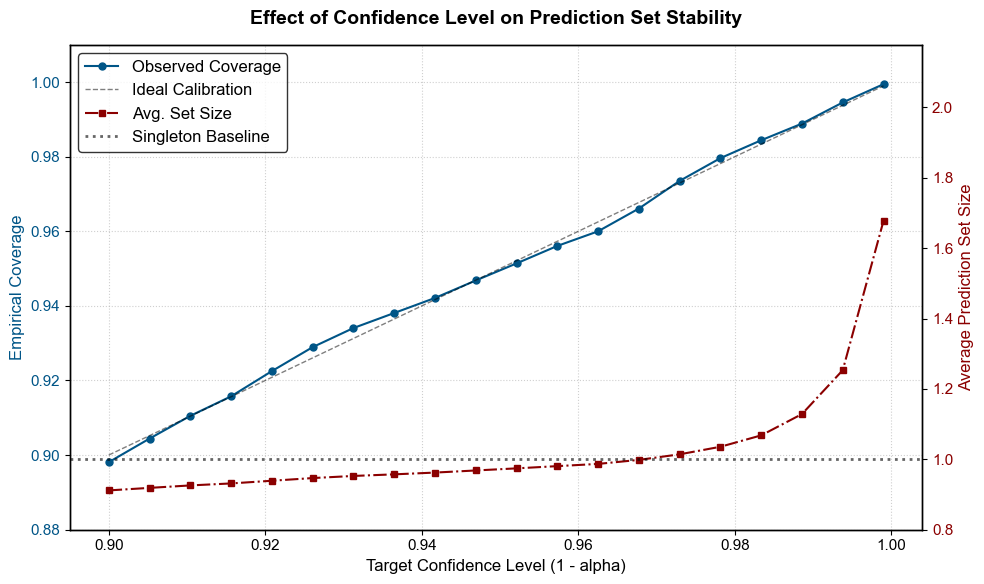

In [29]:
# Diagnostics: empirical coverage vs. average prediction-set size across confidence
# levels (calibrated on validation, evaluated on test).
diag_results = conformal_diagnostics(
    FINAL_MODEL, X_val, y_val, X_test, y_test
)

plot_conformal_diagnostics(
    diag_results,
    title="Effect of Confidence Level on Prediction Set Stability",
    save_path=f"{FINAL_DIR}/conformal/conformal_diagnostics.png",
    dpi=600,
)

In [30]:
# Pick the highest confidence level that still keeps manual review under 5%
# (i.e. automation rate >= 95%).
optimal_conf, df_results = find_optimal_safety_level(
    FINAL_MODEL, X_val, y_val, X_test, target_automation=0.95
)

print("")
print("--- High-safety / low-workload zone (automation > 98%) ---")
display(df_results[df_results["Automation Rate"] > 0.98].tail(5))

Scanning for optimal safety (target automation >= 95.0%)...
Max safety with automation >= 95%: 98.00%

--- High-safety / low-workload zone (automation > 98%) ---


,Confidence (Safety),Automation Rate,Manual Reviews Needed,Avg Set Size
6,0.96,0.983215,154,0.983215
7,0.97,0.995422,42,1.004578


In [31]:
# Final policy at the chosen confidence level, reported on the TEST set.
# This prints BOTH decision layers side by side:
#   * the single validation-tuned threshold (a hard flag / clear decision), and
#   * conformal prediction sets (which can also abstain: "uncertain -> manual review").
final_policy = summarize_conformal_policy(
    FINAL_MODEL, X_val, y_val, X_test, y_test,
    confidence_level=optimal_conf,
    threshold=FINAL_THRESHOLD,
)

=== Conformal policy @ 98.0% confidence (calibrated on validation, evaluated on test) ===
  Total students:            9175
  Cleared (automated safe):  8663
  Flagged (automated risk):  122
  Manual review (uncertain): 390
  Empty set (rare):          0
  Automation rate:           95.7%

=== Threshold policy @ 0.3201 (tuned on validation, applied to test) ===
  Flagged (p >= threshold):  345
  Cleared (p <  threshold):  8830
  Precision (Class 1): 0.6957
  Recall (Class 1): 0.5430
  F1 (Class 1): 0.6099
  Specificity (Class 0 Recall): 0.9880
  ROC AUC: 0.9270
  PR-AUC: 0.6311


# 8. (Optional) Risk-tier stratification

For a tiered-support policy, bucket students into **Low / Moderate / High** risk using the FINAL model's probabilities on the test set. The lower cut is the validation-tuned decision threshold (Low vs. Moderate); the upper cut (0.70) is a policy choice separating "flagged" from "high-confidence" cases. The table shows how the actual weapon-carrying rate rises across tiers — evidence the probabilities are actionable.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_risk_tiers(y_true, y_probs, thresholds=[0.40, 0.70]):
    """
    Segments students into Low, Moderate, and High risk tiers and analyzes accuracy per tier.
    thresholds: [cutoff_low_moderate, cutoff_moderate_high]
    """
    low_cut, high_cut = thresholds
    
    # 1. Assign Tiers
    tiers = []
    for p in y_probs:
        if p < low_cut:
            tiers.append("1. Low Risk")
        elif p < high_cut:
            tiers.append("2. Moderate Risk")
        else:
            tiers.append("3. High Risk")
            
    df = pd.DataFrame({'Actual': y_true, 'Prob': y_probs, 'Tier': tiers})
    
    # 2. Calculate Statistics per Tier
    summary = df.groupby('Tier').agg(
        Total_Students=('Actual', 'count'),
        Weapons_Found=('Actual', 'sum'),
        Mean_Probability=('Prob', 'mean')
    )
    
    # Calculate "Precision" (Actual Weapon Rate) for each tier
    summary['Actual_Risk_Rate'] = summary['Weapons_Found'] / summary['Total_Students']
    
    # Formatting
    summary['Actual_Risk_Rate'] = summary['Actual_Risk_Rate'].apply(lambda x: f"{x:.1%}")
    summary['Mean_Probability'] = summary['Mean_Probability'].apply(lambda x: f"{x:.2f}")
    
    return summary, df

In [33]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

def plot_risk_distribution(tier_df, output_dir, thresholds):
    """
    Plots the risk distribution with dynamic threshold lines.
    thresholds: a list of two values, e.g., [0.3714, 0.70]
    """
    os.makedirs(output_dir, exist_ok=True)

    plt.figure(figsize=(8, 5))
    
    # Color palette matching your tiers
    colors = {"1. Low Risk": "green", "2. Moderate Risk": "orange", "3. High Risk": "red"}
    
    # Create the histogram
    sns.histplot(data=tier_df, x="Prob", hue="Tier", bins=20, 
                 multiple="stack", palette=colors, edgecolor="black")
    
    # --- DYNAMIC LINES ---
    # Line 1: The Optimized Decision Threshold
    plt.axvline(thresholds[0], color='black', linestyle='--', 
                label=f'Decision Threshold ({thresholds[0]:.4f})')
    
    # Line 2: The High Confidence/Tier 3 Threshold
    plt.axvline(thresholds[1], color='black', linestyle=':', 
                label=f'High Confidence ({thresholds[1]:.2f})')
    # ---------------------

    plt.xlabel("Calibrated Weapon Probability")
    plt.ylabel("Number of Students")
    plt.title("Distribution of Students across Risk Tiers")
    plt.legend()
    plt.tight_layout()
    
    plt.savefig(f"{output_dir}/fig_risk_stratification.png", dpi=300)
    plt.show()

--- Risk-tier stratification (test set) ---


,Total_Students,Weapons_Found,Mean_Probability,Actual_Risk_Rate
Tier,,,,
1. Low Risk,8830,202,0.03,2.3%
2. Moderate Risk,166,87,0.49,52.4%
3. High Risk,179,153,0.85,85.5%


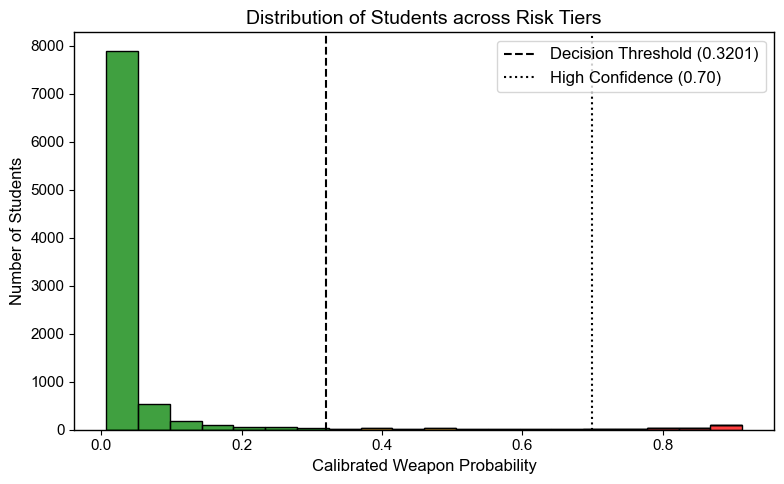

In [34]:
# Risk tiers on the TEST set, using the FINAL model's probabilities.
#   lower cut = the validation-tuned decision threshold (Low vs Moderate),
#   upper cut = 0.70, a policy choice for "high-confidence" cases (Moderate vs High).
tier_thresholds = [FINAL_THRESHOLD, 0.70]

tier_stats, tier_df = analyze_risk_tiers(
    y_test, FINAL_MODEL.predict_proba(X_test)[:, 1], thresholds=tier_thresholds
)
print("--- Risk-tier stratification (test set) ---")
display(tier_stats)

plot_risk_distribution(tier_df, f"{FINAL_DIR}/tiers", thresholds=tier_thresholds)